# Импорт вспомогательных модулей

In [1]:
import csv
import keras
from keras import layers
from keras import regularizers
import numpy as np
import matplotlib.pyplot as plt


2025-03-24 19:40:17.865727: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:10575] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2025-03-24 19:40:17.865780: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:479] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2025-03-24 19:40:17.924823: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1442] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-03-24 19:40:17.970627: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE4.1 SSE4.2 AVX AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


# Подготовка обучающих данных
## Выгрузка данных для обучения из файла

In [2]:
def read_from_file(file_name):
    with open(file_name, mode="r", encoding="utf-8") as csvfile:
        reader = csv.DictReader(csvfile)
        features = reader.fieldnames
        read_data = [
            {feature: row[feature] for feature in features} for row in reader
        ]
    return features, read_data


features, read_data = read_from_file("../data/train.csv")
features
# read_data


['id',
 'day',
 'pressure',
 'maxtemp',
 'temparature',
 'mintemp',
 'dewpoint',
 'humidity',
 'cloud',
 'sunshine',
 'winddirection',
 'windspeed',
 'rainfall']

## Выделение и векторизация обучающих данных

In [3]:
ftrs_to_use = tuple(features[2:-1])
train_data_vectorized = {
    ftr: np.array([row[ftr] for row in read_data], dtype="float32")
    for ftr in ftrs_to_use
}
# train_labels = train_data_vectorized["rainfall"]
train_labels = np.array(
    [row["rainfall"] for row in read_data], dtype="float32"
)
# train_data_raw


In [4]:
train_labels

array([1., 1., 1., ..., 1., 1., 1.], dtype=float32)

## Визуализация исходных данных

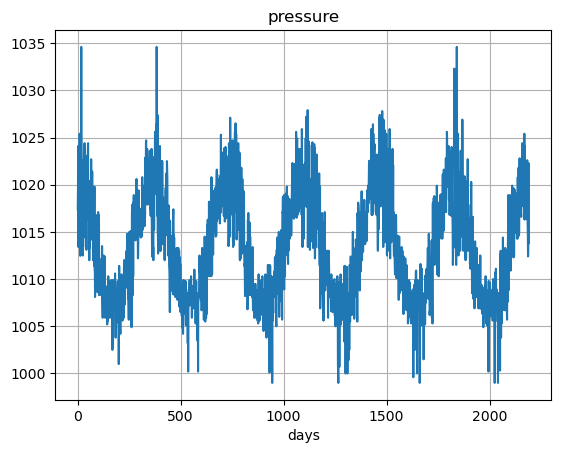

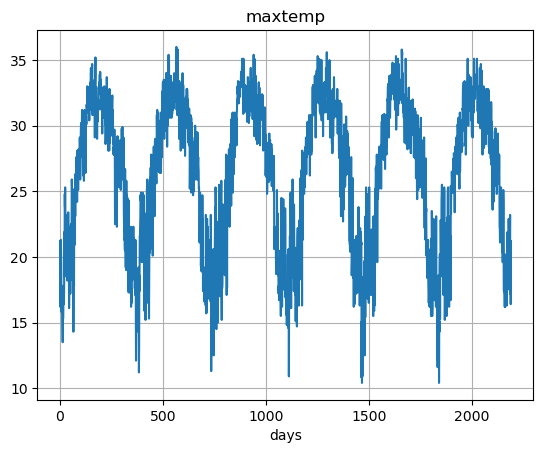

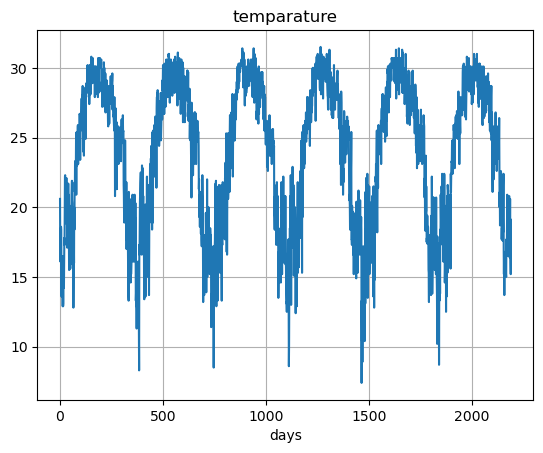

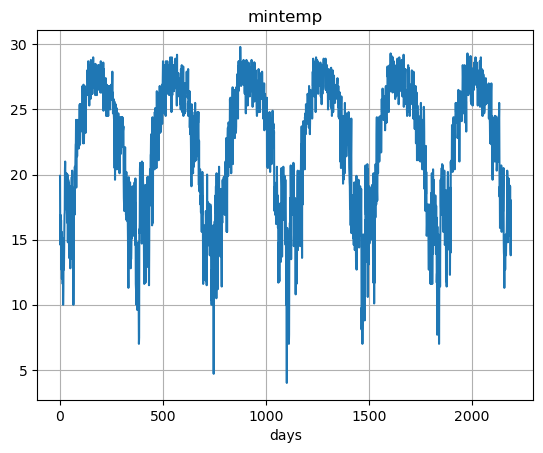

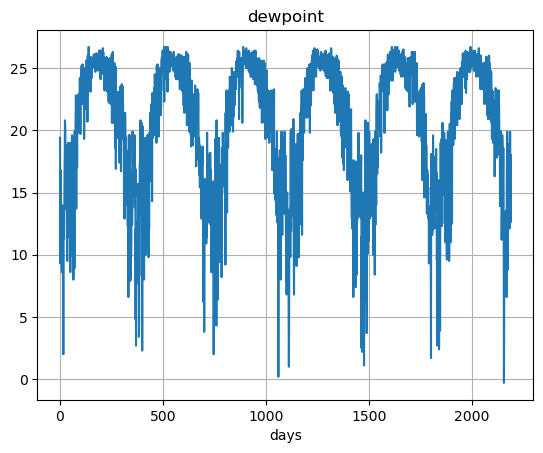

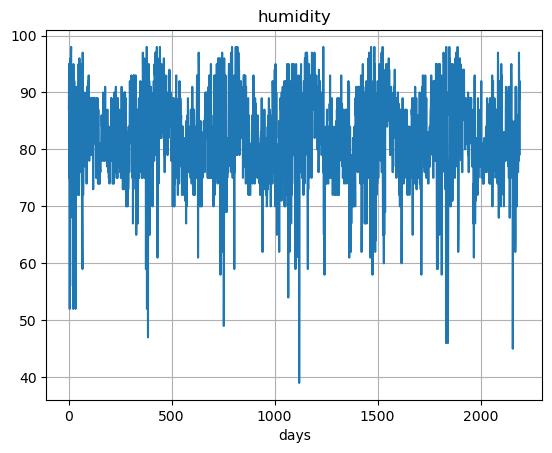

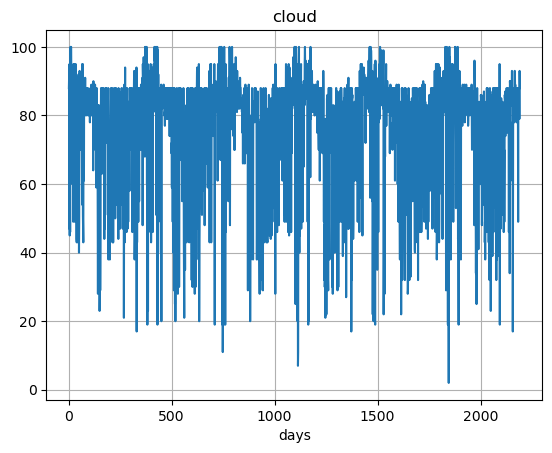

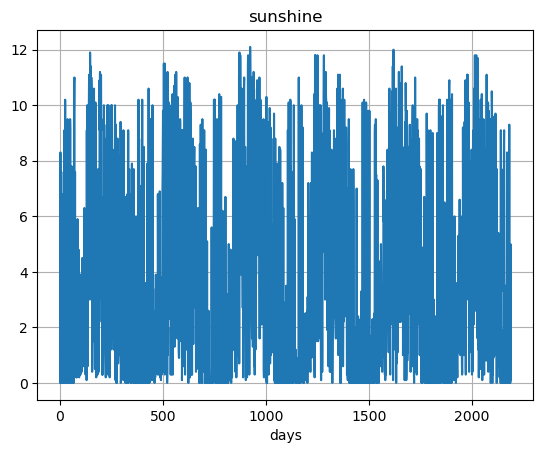

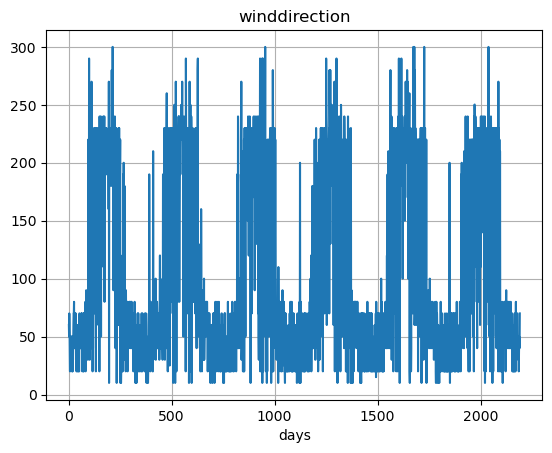

In [5]:
for i, ftr in enumerate(ftrs_to_use[:-1]):
    plt.plot(range(1, len(train_data_vectorized[ftr])+1),
             train_data_vectorized[ftr])
    plt.xlabel("days")
    plt.title(ftr)
    plt.grid()
    plt.show()


## Нормализация значений

In [6]:
def copy_data(data):
    if isinstance(data, dict):
        return {key: data[key].copy() for key in data}
    elif isinstance(data, list):
        return [val for val in data]
    elif isinstance(data, np.ndarray):
        return np.array([val for val in data], dtype="float32")

def normalize_data(data,
                   master=None,
                   *,
                   num_ftrs=None,
                   # ignore=None,
                   **kwargs):
    normalized_data = copy_data(data)
    if master:
        master_data = copy_data(master)
    elif not master:
        master_data = copy_data(data)
    for ftr in num_ftrs:
        mean_val = master_data[ftr].mean(axis=0)
        normalized_data[ftr] -= mean_val
        std_dev = master_data[ftr].std(axis=0)
        normalized_data[ftr] /= std_dev
    for ftr in kwargs:
        normalized_data[ftr] /= kwargs[ftr]
    return normalized_data
    

train_data_normalized = normalize_data(
    train_data_vectorized,
    num_ftrs=("pressure", "maxtemp", "temparature",
              "mintemp", "dewpoint", "windspeed"),
    humidity=100,
    cloud=100,
    winddirection=360
)
train_data_normalized


{'pressure': array([ 0.67172337,  1.0431327 ,  1.8567009 , ..., -0.05342395,
         1.5383486 ,  0.03500786], dtype=float32),
 'maxtemp': array([-0.913809 , -1.798289 , -1.232222 , ..., -1.3029803, -1.7629099,
        -0.913809 ], dtype=float32),
 'temparature': array([-0.6421981, -1.3508452, -1.504066 , ..., -1.465761 , -1.6764396,
        -0.9294874], dtype=float32),
 'mintemp': array([-0.44881532, -1.2594179 , -1.4966674 , ..., -1.5559798 ,
        -1.6548339 , -0.8244604 ], dtype=float32),
 'dewpoint': array([-0.19945674, -0.95600104, -2.109731  , ..., -1.4855819 ,
        -1.0883963 , -0.46424717], dtype=float32),
 'humidity': array([0.87, 0.95, 0.75, ..., 0.79, 0.92, 0.89], dtype=float32),
 'cloud': array([0.88, 0.91, 0.47, ..., 0.79, 0.93, 0.88], dtype=float32),
 'sunshine': array([1.1, 0. , 8.3, ..., 5. , 0.1, 1. ], dtype=float32),
 'winddirection': array([0.16666667, 0.1388889 , 0.19444445, ..., 0.11111111, 0.11111111,
        0.19444445], dtype=float32),
 'windspeed': array

## Формирование датасета обучающих данных

In [15]:
def dict_to_array(data):
    for key in data:
        length = len(data[key])
        break
    return np.array(
        [[data[ftr][i].copy() for ftr in data] for i in range(length)],
        dtype="float32"
    )


train_data_raw = dict_to_array(train_data_normalized)
# num_of_val_samples = len(train_data_raw) // 4
num_of_val_samples = 790
num_of_train_samples = len(train_data_raw) - num_of_val_samples
sequence_length = 5
batch_size = 256
train_dataset = keras.utils.timeseries_dataset_from_array(
    train_data_raw[:-sequence_length],
    targets=train_labels[sequence_length:],
    sequence_length=sequence_length,
    shuffle=True,
    batch_size=batch_size,
    start_index=0,
    end_index=num_of_train_samples
)
val_dataset = keras.utils.timeseries_dataset_from_array(
    train_data_raw[:-sequence_length],
    targets=train_labels[sequence_length:],
    sequence_length=sequence_length,
    shuffle=True,
    batch_size=batch_size,
    start_index=num_of_train_samples
)


In [16]:
# train_dataset = train_dataset.unbatch().batch(batch_size, drop_remainder=True)
# val_dataset = val_dataset.unbatch().batch(batch_size, drop_remainder=True)

In [17]:
num_of_train_samples, num_of_val_samples

(1400, 790)

In [20]:
len(list(val_dataset.as_numpy_iterator()))

2025-03-24 21:57:11.641430: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


4

# Обучение модели
## Компиляция модели

In [21]:
def build_model():
    inputs = layers.Input(shape=(sequence_length, train_data_raw.shape[-1]))
    x = layers.LSTM(32)(inputs)
    outputs = layers.Dense(1, activation="sigmoid")(x)
    model = keras.Model(inputs, outputs)
    return model


model = build_model()
model.compile(optimizer="rmsprop",
              loss="binary_crossentropy",
              metrics=["accuracy"])
model.summary()


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 5, 10)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 32)             │         5,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,537 (21.63 KB)

 Trainable params: 5,537 (21.63 KB)

 Non-trainable params: 0 (0.00 B)

In [22]:
# for samples, labels in train_dataset:
#     print(samples.shape)
#     print(labels.shape)
#     # print(samples)
#     # break
# print()
# for samples, labels in val_dataset:
#     print(samples.shape)
#     print(labels.shape)
#     # print(samples)
#     # break

## Валидация модели

In [23]:
callbacks = [
    keras.callbacks.ModelCheckpoint("rnn-model.keras", save_best_only=True)
]
print("Fitting model...")
history = model.fit(train_dataset,
                    epochs=50,
                    validation_data=val_dataset,
                    callbacks=callbacks,
                    verbose=0)
print("Model has been fitted.")


Fitting model...


2025-03-24 21:57:30.624740: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:465] Loaded cuDNN version 8907


Model has been fitted.


## Визуализация результатов валидации

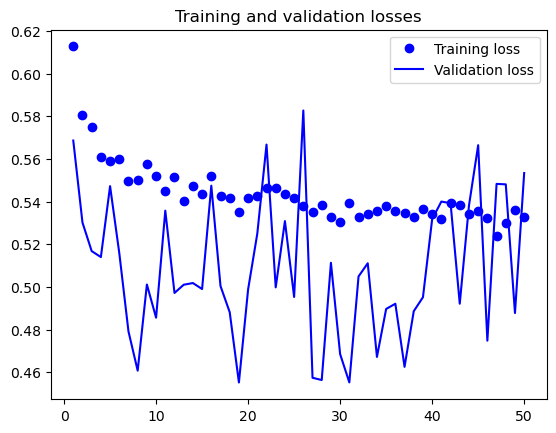

In [24]:
import matplotlib.pyplot as plt
loss = history.history["loss"]
val_loss = history.history["val_loss"]
epochs = range(1, len(loss) + 1)
plt.figure()
plt.plot(epochs, loss, "bo", label="Training loss")
plt.plot(epochs, val_loss, "b", label="Validation loss")
plt.title("Training and validation losses")
plt.legend()
plt.show()


## Определение эпохи переобучения

In [25]:
overfitting_epoch = val_loss.index(min(val_loss))
print(f"Model began to overfit at {overfitting_epoch+1} epoch")
print(f"Validation accuracy at {overfitting_epoch+1} epoch:"
      f""" {round(history.history["val_accuracy"][overfitting_epoch], 5)}""")
print(f"Validation loss at {overfitting_epoch+1} epoch:"
      f" {round(val_loss[overfitting_epoch], 5)}")


Model began to overfit at 19 epoch
Validation accuracy at 19 epoch: 0.77593
Validation loss at 19 epoch: 0.45521


# Подготовка контрольных данных
## Выгрузка контрольных данных

In [14]:
_, read_data = read_from_file("../data/test.csv")
read_data


[{'id': '2190',
  'day': '1',
  'pressure': '1019.5',
  'maxtemp': '17.5',
  'temparature': '15.8',
  'mintemp': '12.7',
  'dewpoint': '14.9',
  'humidity': '96.0',
  'cloud': '99.0',
  'sunshine': '0.0',
  'winddirection': '50.0',
  'windspeed': '24.3'},
 {'id': '2191',
  'day': '2',
  'pressure': '1016.5',
  'maxtemp': '17.5',
  'temparature': '16.5',
  'mintemp': '15.8',
  'dewpoint': '15.1',
  'humidity': '97.0',
  'cloud': '99.0',
  'sunshine': '0.0',
  'winddirection': '50.0',
  'windspeed': '35.3'},
 {'id': '2192',
  'day': '3',
  'pressure': '1023.9',
  'maxtemp': '11.2',
  'temparature': '10.4',
  'mintemp': '9.4',
  'dewpoint': '8.9',
  'humidity': '86.0',
  'cloud': '96.0',
  'sunshine': '0.0',
  'winddirection': '40.0',
  'windspeed': '16.9'},
 {'id': '2193',
  'day': '4',
  'pressure': '1022.9',
  'maxtemp': '20.6',
  'temparature': '17.3',
  'mintemp': '15.2',
  'dewpoint': '9.5',
  'humidity': '75.0',
  'cloud': '45.0',
  'sunshine': '7.1',
  'winddirection': '20.0',
  '

## Выделение и векторизация контрольных данных

In [15]:
read_data[517]["winddirection"] = 100

In [16]:
test_data_vectorized = {
    ftr: np.array([row[ftr] for row in read_data], dtype="float32")
    for ftr in ftrs_to_use if ftr != "rainfall"
}
# test_data_vectorized


## Нормализация значений

In [17]:
test_data_normalized = normalize_data(
    test_data_vectorized,
    train_data_vectorized,
    num_ftrs=("pressure", "maxtemp", "temparature",
              "mintemp", "dewpoint", "windspeed"),
    humidity=100,
    cloud=100,
    winddirection=360
)
test_data_normalized


{'pressure': array([ 1.0431327 ,  0.5125418 ,  1.8213369 ,  1.6444732 ,  1.5206665 ,
         2.3872917 ,  1.5914055 , -0.01804907,  1.361485  ,  2.2104282 ,
         0.6894054 ,  1.3968599 ,  0.9547008 , -0.19491269,  1.732905  ,
         1.6090983 ,  2.0512466 ,  1.8567009 ,  2.0866323 ,  1.8567009 ,
         3.2892919 ,  1.8567009 ,  2.175064  ,  0.12343966, -0.19491269,
        -0.19491269, -0.01804907, -0.19491269,  0.05270069,  0.7778372 ,
         0.28262123,  0.05270069,  0.22956431,  1.5206665 ,  0.6894054 ,
         0.22956431,  0.1411325 ,  0.40642792,  1.3791778 ,  0.5655987 ,
        -0.03573111,  0.15881455,  1.5914055 ,  0.6894054 ,  1.6090983 ,
         1.308428  ,  0.03500786,  0.6186556 ,  1.2023141 ,  1.5737234 ,
         0.848587  ,  0.1411325 ,  0.6009736 ,  0.848587  ,  0.22956431,
         0.9900757 , -0.23028757,  0.91932595, -0.1595378 , -0.28334448,
         1.3791778 ,  0.76015514,  1.0077578 ,  1.290746  , -0.23028757,
         1.6798373 ,  1.0785075 ,  0.49

## Формирование датасета контрольных данных

In [22]:
test_data_raw = dict_to_array(test_data_normalized)
test_dataset = keras.utils.timeseries_dataset_from_array(
    test_data_raw,
    None,
    sequence_length=sequence_length,
    # shuffle=True,
    batch_size=batch_size
)


# Формирование предсказаний
## Получение вероятности выпадения осадков

In [23]:
model = keras.saving.load_model("rnn-model.keras")

In [24]:
predictions_raw = model.predict(test_dataset, verbose=0)
predictions_raw


array([[0.59184116],
       [0.6605005 ],
       [0.68273926],
       [0.72390985],
       [0.7688098 ],
       [0.7722409 ],
       [0.78383493],
       [0.6574163 ],
       [0.7161397 ],
       [0.7482696 ],
       [0.7054753 ],
       [0.5582098 ],
       [0.6500376 ],
       [0.65080297],
       [0.5024504 ],
       [0.48253098],
       [0.47403276],
       [0.5063425 ],
       [0.60603046],
       [0.6968454 ],
       [0.74399996],
       [0.74971974],
       [0.66811335],
       [0.75216115],
       [0.7772664 ],
       [0.7232517 ],
       [0.7887201 ],
       [0.8476163 ],
       [0.8450985 ],
       [0.8603006 ],
       [0.86869943],
       [0.86910135],
       [0.80603874],
       [0.8161437 ],
       [0.8130485 ],
       [0.8100746 ],
       [0.8033269 ],
       [0.8317606 ],
       [0.6997714 ],
       [0.7475157 ],
       [0.7606823 ],
       [0.6065653 ],
       [0.5575317 ],
       [0.67696047],
       [0.57074285],
       [0.66796625],
       [0.72059697],
       [0.779

## Округление значений до целого

In [27]:
predictions = [
    round(prediction[0], 1) for prediction in predictions_raw
]
# predictions = [1. for _ in read_data]
predictions


[0.6,
 0.7,
 0.7,
 0.7,
 0.8,
 0.8,
 0.8,
 0.7,
 0.7,
 0.7,
 0.7,
 0.6,
 0.7,
 0.7,
 0.5,
 0.5,
 0.5,
 0.5,
 0.6,
 0.7,
 0.7,
 0.7,
 0.7,
 0.8,
 0.8,
 0.7,
 0.8,
 0.8,
 0.8,
 0.9,
 0.9,
 0.9,
 0.8,
 0.8,
 0.8,
 0.8,
 0.8,
 0.8,
 0.7,
 0.7,
 0.8,
 0.6,
 0.6,
 0.7,
 0.6,
 0.7,
 0.7,
 0.8,
 0.8,
 0.8,
 0.8,
 0.8,
 0.8,
 0.8,
 0.8,
 0.9,
 0.8,
 0.8,
 0.8,
 0.8,
 0.8,
 0.7,
 0.6,
 0.7,
 0.7,
 0.7,
 0.8,
 0.8,
 0.9,
 0.9,
 0.9,
 0.9,
 0.9,
 0.9,
 0.8,
 0.8,
 0.8,
 0.9,
 0.8,
 0.8,
 0.9,
 0.9,
 0.9,
 0.9,
 0.9,
 0.9,
 0.9,
 0.9,
 0.9,
 0.9,
 0.9,
 0.9,
 0.9,
 0.9,
 0.9,
 0.8,
 0.8,
 0.8,
 0.9,
 0.9,
 0.9,
 0.9,
 0.9,
 0.9,
 0.9,
 0.9,
 0.9,
 0.8,
 0.8,
 0.9,
 0.9,
 0.9,
 0.9,
 0.9,
 0.9,
 0.9,
 0.8,
 0.8,
 0.8,
 0.7,
 0.7,
 0.7,
 0.8,
 0.9,
 0.9,
 0.9,
 0.9,
 0.9,
 0.8,
 0.8,
 0.9,
 0.9,
 0.9,
 0.9,
 0.9,
 0.9,
 0.9,
 0.8,
 0.6,
 0.7,
 0.8,
 0.8,
 0.9,
 0.8,
 0.8,
 0.7,
 0.7,
 0.7,
 0.8,
 0.6,
 0.7,
 0.7,
 0.7,
 0.7,
 0.8,
 0.8,
 0.7,
 0.8,
 0.7,
 0.6,
 0.6,
 0.5,
 0.6,
 0.7,
 0.8,
 0.7,
 0.8

## Запись результатов в файл

In [28]:
with open("../data/submission.csv", mode="w", encoding="utf-8", newline='') as csvfile:
    writer = csv.DictWriter(csvfile, fieldnames=["id", "rainfall"])
    writer.writeheader()
    for i, prediction in enumerate(predictions):
        writer.writerow(
            {
                "id": read_data[i]["id"],
                "rainfall": prediction
            }
        )
    print("File has been written.")


File has been written.
